# ADAN8888 — Week 9: Select the Winning Model

## ===== WEEK 9 START =====

**Task:** Compare all 9 previously trained configurations from Weeks 6–8 on the **same validation partition**. Lock the lowest-validation-MAE winner; build the bias–variance diagnostic; then evaluate **only that already-selected model** against the untouched final test period.

**Crucial:** Weeks 6–8 intentionally did not evaluate test data; Week 9 explicitly requires the final test evaluation.

## 1. Load the reusable Week 9 audit module

The notebook delegates to a single source implementation to prevent a separate, inconsistent modeling recipe.

In [3]:
from pathlib import Path
import importlib.util
import sys
import json
import numpy as np
from IPython.display import display, Image

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'Src' / 'week9_src_select_and_final_test.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the existing ADAN8888 repository in VS Code.')
source_file = ROOT / 'Src' / 'week9_src_select_and_final_test.py'
spec = importlib.util.spec_from_file_location('week9_model_audit', source_file)
week9 = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = week9
spec.loader.exec_module(week9)
OUT = ROOT / 'Reports' / 'week9'
TABLES = OUT / 'week9_tables'
FIGURES = OUT / 'week9_figures'
print('Source module: Src/week9_src_select_and_final_test.py')
print('Historical validation sources: Reports/week6, Reports/week7, Reports/week8')

Source module: Src/week9_src_select_and_final_test.py
Historical validation sources: Reports/week6, Reports/week7, Reports/week8


## 2. Audit and rank all nine models using validation data only

Week 6: Ridge_A/Ridge_B/Ridge_C; Week 7: HGB_A/HGB_B/HGB_C; Week 8: MLP_A/MLP_B/MLP_C. The source prefers the original saved Week 6–8 metric CSVs; otherwise it uses the provided verified reference values (the Week 6 PDF was rounded to three decimal places).

**Selection criterion:** minimum validation MAE, followed by validation RMSE and then a declared heuristic complexity order for exact ties. No test labels are consulted in this step. The source writes `week9_selection_lock.json` before any test scoring.

In [4]:
selection = week9.select_and_lock(ROOT)
display(selection.comparison[['Model','Family','Configuration','Training_MAE','Validation_MAE','Training_RMSE','Validation_RMSE','Training_R2','Validation_R2']].round(3))
print('Validation ranking (best to worst):')
display(selection.ranking[['Model','Validation_MAE','Validation_RMSE']].round(3))
print('LOCKED winner:', selection.winner)
assert len(selection.comparison) == 9
assert len(selection.ranking) == 9
assert selection.winner == 'MLP_B'  # Expected from verified Week 6–8 results
assert selection.lock['TestDataViewedForSelection'] is False
assert selection.lock_path.is_file()

,Model,Family,Configuration,Training_MAE,Validation_MAE,Training_RMSE,Validation_RMSE,Training_R2,Validation_R2
0,Ridge_C,Ridge,alpha=1000000,3395.138,3418.394,5985.650,6163.435,0.405,0.422
1,Ridge_B,Ridge,alpha=10000,3332.425,3259.035,5789.185,5890.276,0.443,0.473
2,Ridge_A,Ridge,alpha=1,3331.959,3257.177,5787.133,5887.098,0.444,0.473
3,HGB_A,HGB,lr=0.05; iter=100; leaves=15,1180.219,1179.315,2263.184,2060.216,0.915,0.935
4,HGB_B,HGB,lr=0.05; iter=250; leaves=15,1164.083,1163.470,2254.863,2050.414,0.916,0.936
5,HGB_C,HGB,lr=0.05; iter=250; leaves=31,1159.017,1161.068,2247.904,2051.788,0.916,0.936
6,MLP_A,MLP,hidden=32-16; parameters=641,1171.375,1171.512,2236.708,2019.431,0.917,0.938
7,MLP_B,MLP,hidden=64-32; parameters=2305,1161.628,1143.195,2236.203,1988.778,0.917,0.940
8,MLP_C,MLP,hidden=64-32-16; parameters=2817,1159.014,1149.899,2230.234,1999.785,0.917,0.939


Validation ranking (best to worst):


,Model,Validation_MAE,Validation_RMSE
0,MLP_B,1143.195,1988.778
1,MLP_C,1149.899,1999.785
2,HGB_C,1161.068,2051.788
3,HGB_B,1163.470,2050.414
4,MLP_A,1171.512,2019.431
5,HGB_A,1179.315,2060.216
6,Ridge_A,3257.177,5887.098
7,Ridge_B,3259.035,5890.276
8,Ridge_C,3418.394,6163.435


LOCKED winner: MLP_B


## 3. Bias–variance diagnostic across nine configurations

**Interpretation caution:** these are **observed training and validation mean squared errors**. Within Ridge, increasing L2 regularization reduces effective capacity; within HGB/MLP, more iterations, leaves, layers or neurons tend to increase capacity. **The relative complexity ranking across different model families cannot be measured on a single universal scale.** The plotted x-axis is a course-required, approximate/illustrative progression, not a mathematically proven ordering.

week9_figure_nine_model_bias_variance_diagnostic.png


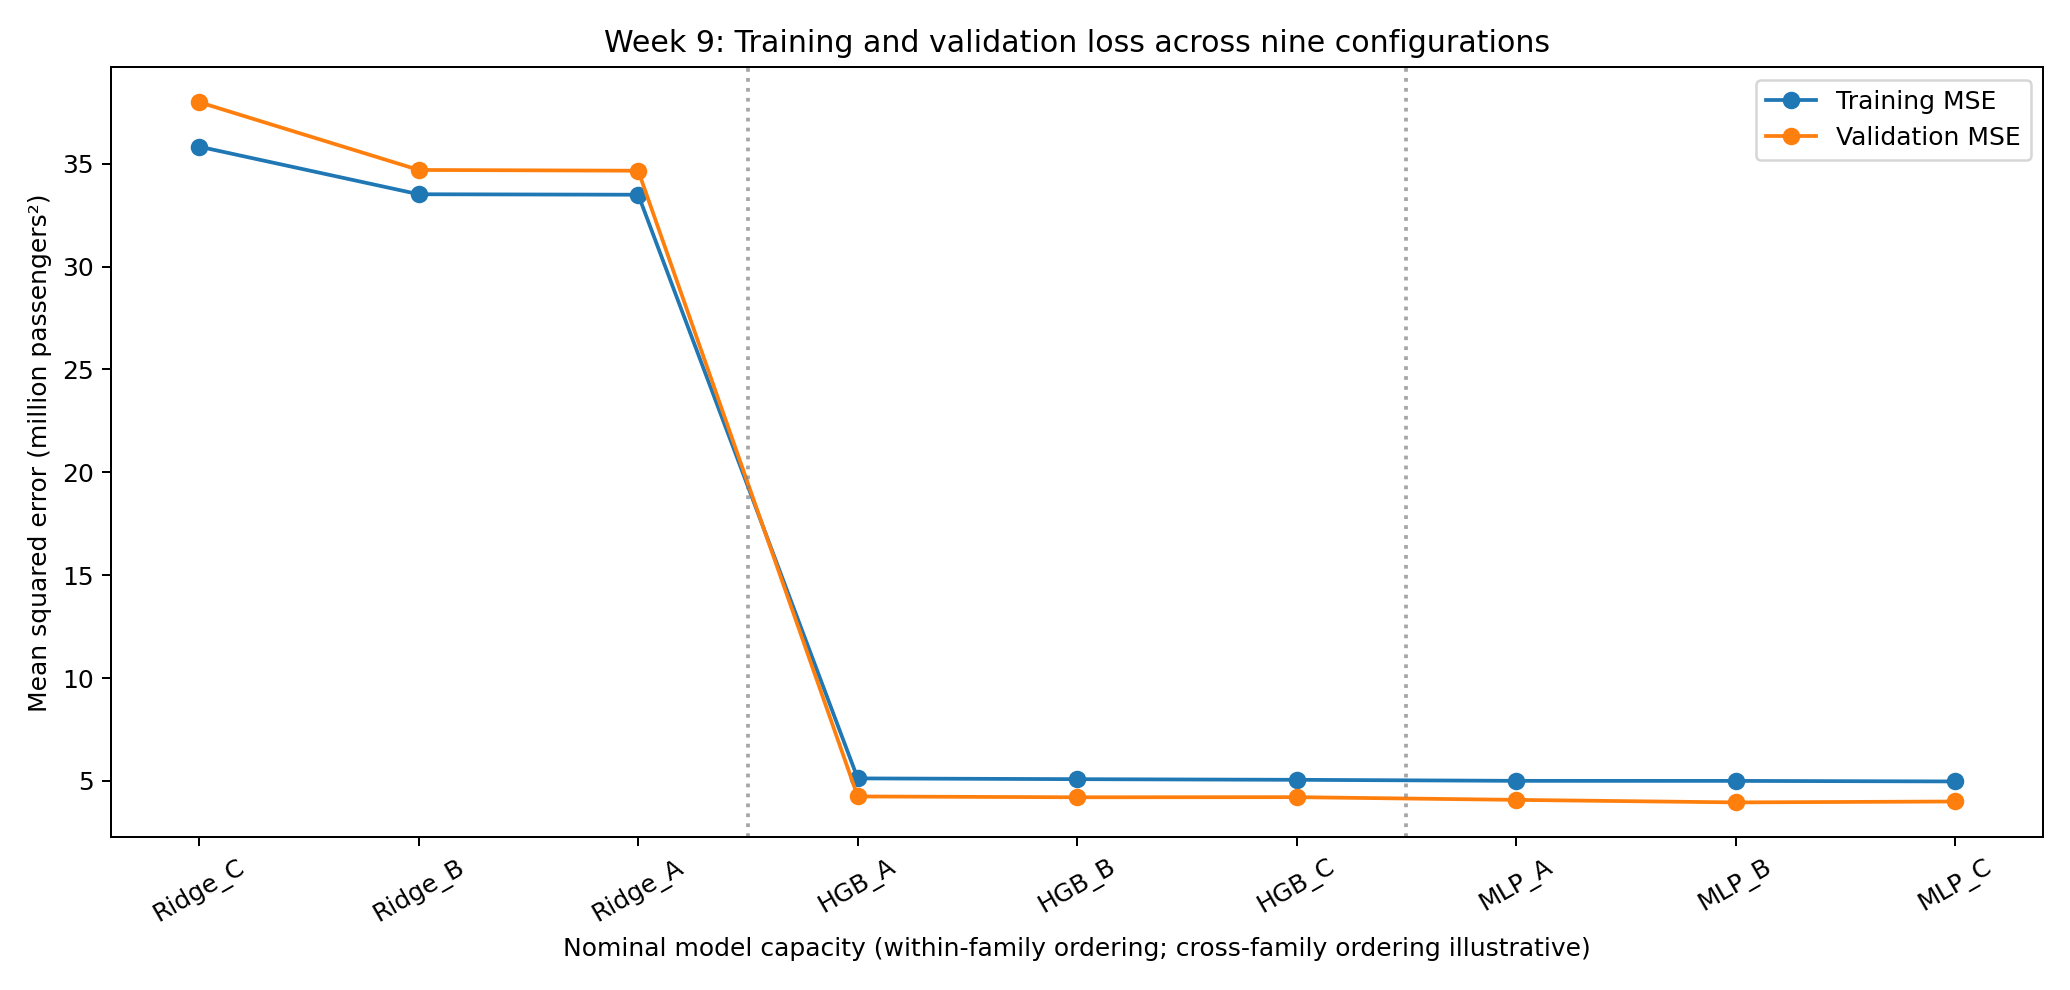

week9_figure_nine_model_validation_mae.png


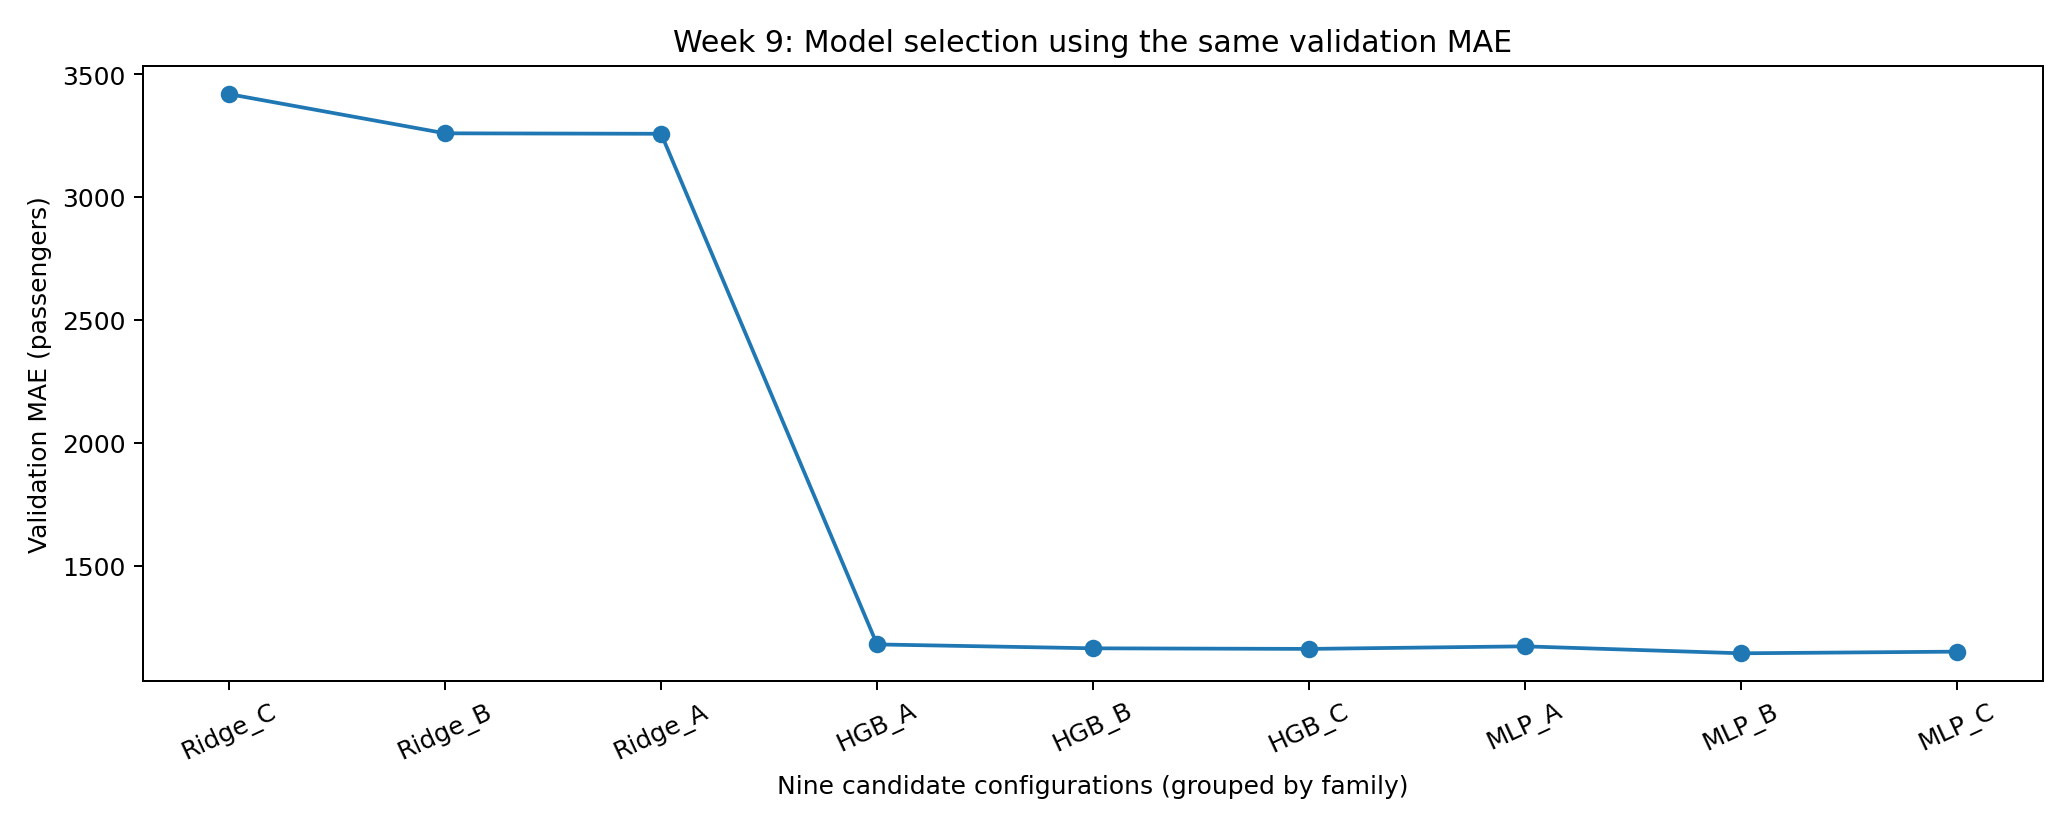

In [5]:
for filename in ['week9_figure_nine_model_bias_variance_diagnostic.png',
                 'week9_figure_nine_model_validation_mae.png']:
    assert (FIGURES / filename).exists()
    print(filename)
    display(Image(filename=str(FIGURES / filename)))

## 4. Final test: evaluate the locked, previously fitted MLP_B **once**

The saved model must exist at `Models/week8/week8_selected_mlp_neural_network.joblib`. The original Week 5 pipeline is recreated on the full official BTS data to obtain the same PC1/PC2 projection. The code **first reproduces MLP_B's historical validation MAE and RMSE within tight tolerance**. If either differs materially, the code refuses to evaluate the test set, preventing a mismatched model/preprocessing evaluation.

Only after this validation gate passes does the preselected model predict the final 264,291 test rows. The result and test plots are saved. **If a finalized test summary already exists, the notebook will reuse it instead of scoring test again.**

In [6]:
test_result = week9.final_test_once(ROOT, selection)
week9.write_report_values(ROOT, selection, test_result)
print('Selected model:', test_result['SelectedModel'])
print('Final test MAE (passengers):', f"{test_result['FinalTestMAE']:,.2f}")
print('Final test RMSE (passengers):', f"{test_result['FinalTestRMSE']:,.2f}")
print('Final test R²:', f"{test_result['FinalTestR2']:.4f}")
print('Validation-reproduction audit passed:', test_result['ValidationConsistencyCheckPassed'])
assert test_result['SelectedModel'] == selection.winner
assert test_result['TestLabelsUsedToSelectModel'] is False
assert test_result['RefitOnTestData'] is False

Selected model: MLP_B
Final test MAE (passengers): 1,122.50
Final test RMSE (passengers): 1,935.24
Final test R²: 0.9390
Validation-reproduction audit passed: True


## 5. Final winning model: training, validation and held-out test metrics

The training and validation metrics are imported unchanged from Week 8's actual model comparison. The test metrics are computed using the frozen, prior-training-fitted MLP_B model. The test period is not used to make new model/parameter decisions.

In [7]:
from pandas import read_csv
winner_table = read_csv(TABLES / 'week9_winner_train_validation_test_metrics.csv')
display(winner_table.round(4))
assert list(winner_table.Partition) == ['Training','Validation','Test']
assert len(winner_table) == 3
assert winner_table.loc[winner_table.Partition.eq('Test'),'Rows'].iloc[0] == 264291

,Partition,Rows,MAE,RMSE,R2
0,Training,1062603,1161.6278,2236.2033,0.9169
1,Validation,239395,1143.1952,1988.7780,0.9399
2,Test,264291,1122.5049,1935.2387,0.9390


## 6. Inspect final test diagnostic figures

The actual-versus-predicted scatter uses at most 4,000 points *for visualization only*. All reported metrics and monthly errors use the **full test partition**.

week9_figure_test_actual_vs_predicted.png


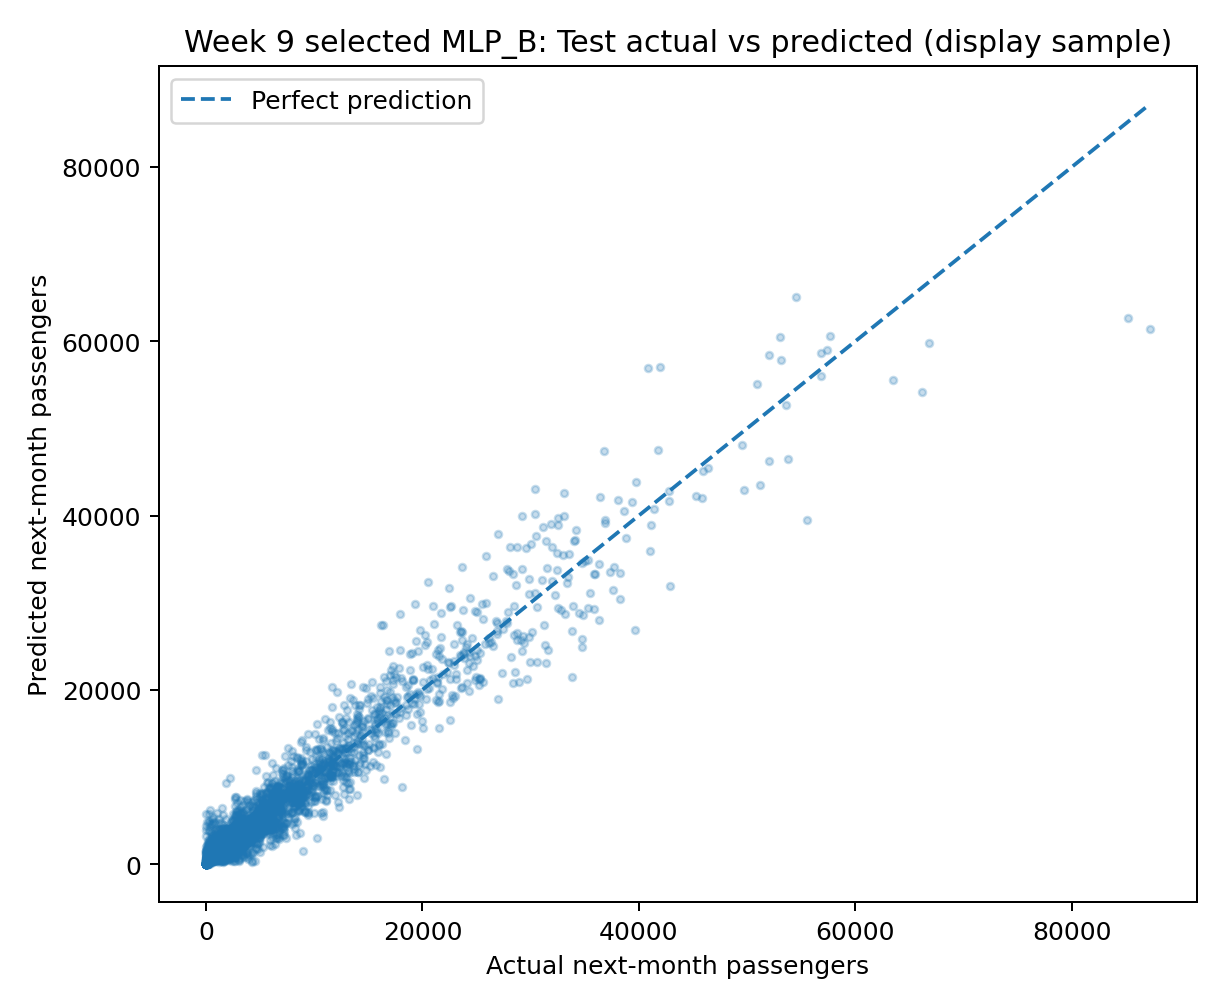

week9_figure_test_monthly_mae.png


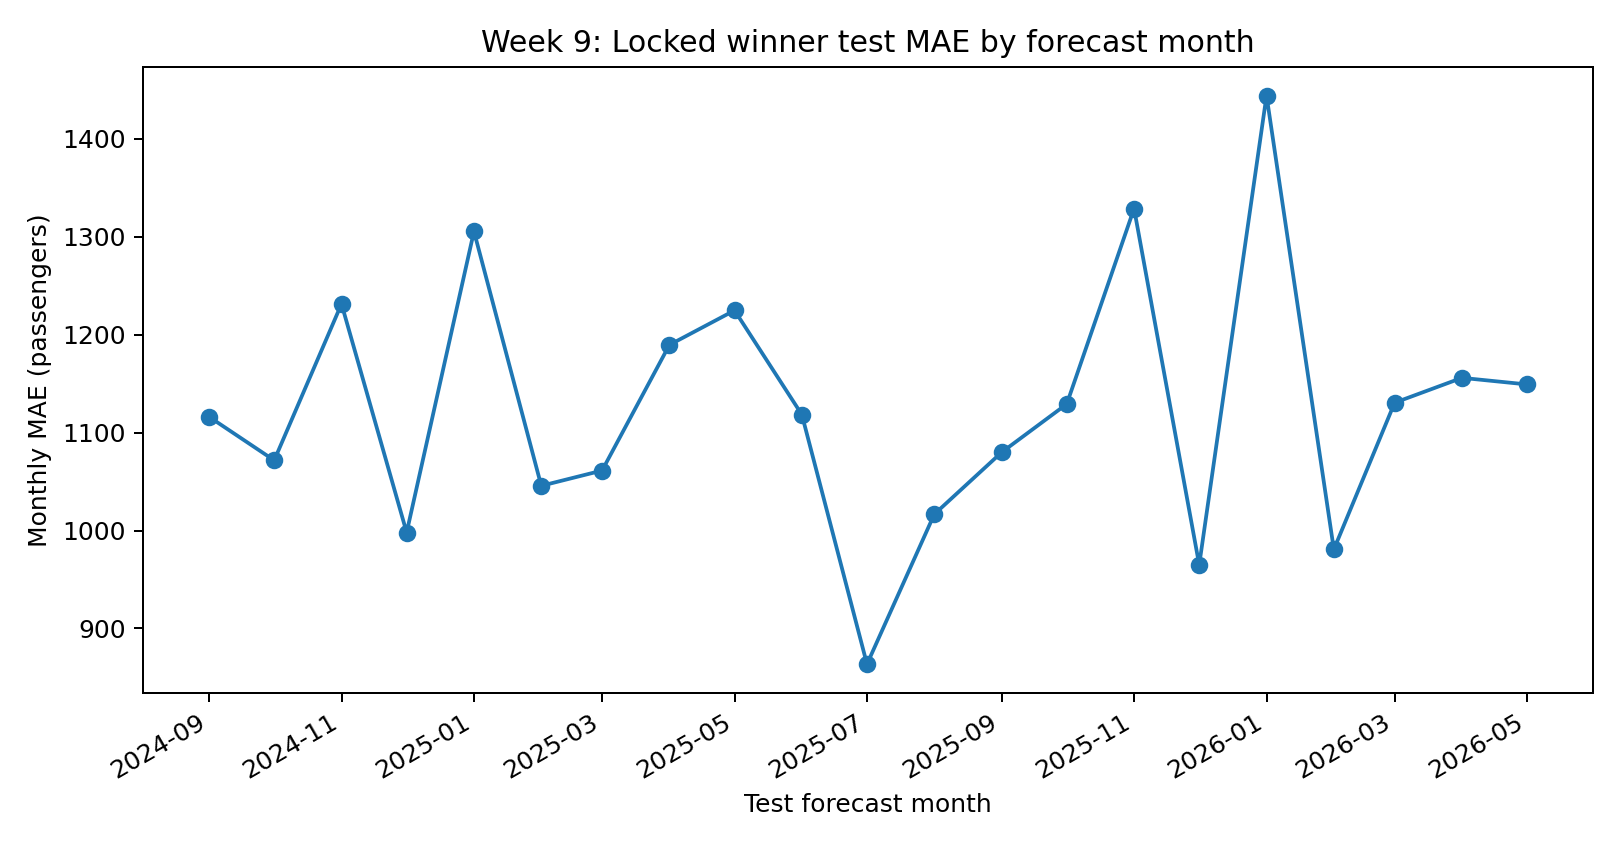

In [8]:
for filename in ['week9_figure_test_actual_vs_predicted.png','week9_figure_test_monthly_mae.png']:
    assert (FIGURES / filename).is_file(), filename
    print(filename)
    display(Image(filename=str(FIGURES / filename)))

## 7. Final checks, reproducibility and report input

The integrity checks below verify that the nine historical scores, the fixed selection decision, and the single test-result record are available. The final written report should compare all nine validation results; discuss the training–validation complexity chart; and answer whether final **test** MAE/RMSE/R² are adequate for deployment. That last judgment requires an explicit airline planning tolerance or comparison to a business baseline; a good validation score alone does not establish readiness.

**Note:** This is a retrospective held-out test of an already-fitted model. It is not a deployment benchmark for forecasts made before BTS data are published.

In [9]:
assert (TABLES / 'week9_nine_model_comparison.csv').is_file()
assert (TABLES / 'week9_validation_ranking.csv').is_file()
assert (TABLES / 'week9_selection_lock.json').is_file()
assert (TABLES / 'week9_test_winner_summary.json').is_file()
assert (TABLES / 'week9_winner_train_validation_test_metrics.csv').is_file()
assert (OUT / 'week9_verified_results_for_report.md').is_file()
assert len(selection.comparison) == 9
assert test_result['TestEvaluatedAfterSelectionLock'] is True
assert np.isfinite([test_result['FinalTestMAE'],test_result['FinalTestRMSE'],test_result['FinalTestR2']]).all()
print('All Week 9 checks passed.')
print('===== WEEK 9 END =====')

All Week 9 checks passed.
===== WEEK 9 END =====
